# FeatureForge tour: from a spec to a measured service

This notebook follows one feature from its YAML spec to the numbers of the serving service. It runs
without Docker: the reference implementation needs no infrastructure, the serving part uses a stand-in
for Redis, and the measurements are the reports that are checked in under `docs/benchmarks/`.

Setup: `pip install -e ".[dev,notebook]"`. The measurements are local, from one laptop, and no
production numbers.

In [1]:
import json
import os
import subprocess
import sys
import warnings
from datetime import UTC, datetime, timedelta
from pathlib import Path
from unittest.mock import Mock

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
print("repository:", ROOT.name)

Matplotlib is building the font cache; this may take a moment.


repository: featureforge


## 1. A feature is a YAML spec

One spec describes the window, the aggregation, the freshness target and the online store. The same
file drives the Flink job, the Spark backfill, the stores and the training datasets.

In [2]:
print(Path("feature_repo/specs/user_play_count_1h.yaml").read_text())

name: user_play_count_1h
version: 1
owner: personalization-team
description: Number of plays in the last hour
entity: user_id
source: interaction-events.validated.v1
aggregations:
  - {name: play_count, op: count, filter: "event_type == 'play'"}
window: {size: 1h, slide: 1m, boundary: right_closed}
lateness: {watermark_delay: 10m, allowed: 30m}
dedupe: {key: event_id, ttl: 24h}
online: {store: redis, ttl: 2h, update_policy: append_only}
offline: {store: iceberg, table: features.user_play_count_1h}
freshness_slo: 5m


In [3]:
specs = sorted(str(path) for path in Path("feature_repo/specs").glob("*.yaml"))
done = subprocess.run(
    [sys.executable, "-m", "featureforge.spec.loader", *specs], capture_output=True, text=True
)
print(done.stdout)
print("exit code", done.returncode)

✓ feature_repo/specs/content_play_count_1h.yaml: content_play_count_1h v1
✓ feature_repo/specs/user_play_count_1h.yaml: user_play_count_1h v1
✓ feature_repo/specs/user_skip_rate_24h.yaml: user_skip_rate_24h v1

exit code 0


## 2. The reference evaluates the spec

The reference is exact event-time arithmetic on the golden fixture. It is the oracle that the Flink job
and the Spark backfill have to match.

In [4]:
from featureforge.spec.loader import load_spec
from featureforge.spec.reference import evaluate_spec
from featureforge.streaming.contracts.events import InteractionEventV1

spec = load_spec("feature_repo/specs/user_play_count_1h.yaml")
lines = Path("fixtures/streaming/user_play_count_1h_v1.jsonl").read_text().splitlines()
events = [InteractionEventV1.model_validate_json(line) for line in lines if line.strip()]
at = datetime(2026, 1, 1, 12, tzinfo=UTC)
for user in ("user_000001", "user_000002", "user_unknown"):
    result = evaluate_spec(spec, events, entity={"user_id": user}, observation_time=at)
    print(user, result.values)

user_000001 {'play_count': 3}
user_000002 {'play_count': 1}
user_unknown {'play_count': 0}


In [5]:
done = subprocess.run(
    [
        sys.executable,
        "-m",
        "featureforge.cli",
        "test-spec",
        "feature_repo/specs/user_play_count_1h.yaml",
        "--events",
        "fixtures/streaming/user_play_count_1h_v1.jsonl",
        "--entity",
        "user_id=user_000001",
        "--at",
        "2026-01-01T11:30:00+00:00",
        "--expect",
        "play_count=3",
    ],
    capture_output=True,
    text=True,
)
print(done.stdout)
print("exit code", done.returncode)

user_play_count_1h · user_id=user_000001
Window (2026-01-01T10:30:00+00:00, 2026-01-01T11:30:00+00:00] · 8 events read
┏━━━━━━━━━━━━┳━━━━━━━━┓
┃ value      ┃ result ┃
┡━━━━━━━━━━━━╇━━━━━━━━┩
│ play_count │ 3      │
└────────────┴────────┘
✓ play_count = 3

exit code 0


## 3. Serving: a value and a status for every entry

A request names features and entities. Every entry comes back with a status (`ok`, `missing`, `stale`
or `backend_error`) and never as a silent zero. This cell uses the real `FeatureServer` and the real
`RedisServingReader` with a stand-in for Redis, so it needs no Docker. The same code runs against Redis
and Cassandra in the service (`make quickstart`).

In [6]:
from featureforge.feature_service import FailPolicyError, FeatureRef, FeatureServer
from featureforge.redis_serving_reader import RedisServingReader
from featureforge.spec.reference import evaluate_expression
from featureforge.streaming.contracts.feature_record import stamp

play = load_spec("feature_repo/specs/user_play_count_1h.yaml")
reference = datetime(2026, 11, 20, 12, tzinfo=UTC)
fresh = reference - play.freshness_slo / 2
old = reference - play.freshness_slo * 3
users = ["user_000001", "user_000002", "user_000003"]


def payload(user, observation, count):
    counts = {"play_count": count}
    data = {
        "feature_schema_version": "v1",
        "feature_name": play.name,
        play.keys[0]: user,
        "observation_time": stamp(observation),
        "window_start_exclusive": stamp(observation - timedelta(hours=1)),
        **counts,
    }
    for name, expression in play.derived.items():
        data[name] = evaluate_expression(expression, counts)
    return json.dumps(data)


def key(user):
    return f"ns:v{play.version}:{play.name}:{user}"


store = {key(users[0]): payload(users[0], fresh, 3), key(users[1]): payload(users[1], old, 5)}
stand_in = Mock()
stand_in.mget.side_effect = lambda keys: [store.get(k) for k in keys]
server = FeatureServer(RedisServingReader(stand_in, [play], namespace="ns"), [play])
entities = [{play.keys[0]: user} for user in users]

result = server.lookup([FeatureRef(play.name)], entities, reference_time=reference)
for user, entry in zip(users, result.entries, strict=True):
    print(user, entry.status)
print(json.dumps(result.to_dict(), indent=2, default=str)[:1500])

user_000001 ok
user_000002 stale
user_000003 missing
{
  "reference_time": "2026-11-20T12:00:00+00:00",
  "atomic": false,
  "elapsed_ms": 0.071,
  "entries": [
    {
      "feature": "user_play_count_1h",
      "version": 1,
      "entity": {
        "user_id": "user_000001"
      },
      "status": "ok",
      "values": {
        "play_count": 3
      },
      "observation_time": "2026-11-20T11:57:30+00:00",
      "age_seconds": 150.0,
      "freshness": "fresh",
      "published_at": null,
      "defaulted": false,
      "error_type": null
    },
    {
      "feature": "user_play_count_1h",
      "version": 1,
      "entity": {
        "user_id": "user_000002"
      },
      "status": "stale",
      "values": {
        "play_count": 5
      },
      "observation_time": "2026-11-20T11:45:00+00:00",
      "age_seconds": 900.0,
      "freshness": "stale",
      "published_at": null,
      "defaulted": false,
      "error_type": null
    },
    {
      "feature": "user_play_count_1h",
 

In [7]:
down = Mock()
down.mget.side_effect = ConnectionError("redis is down")
broken = FeatureServer(RedisServingReader(down, [play], namespace="ns"), [play])
try:
    result = broken.lookup([FeatureRef(play.name)], entities, reference_time=reference)
    print([entry.status for entry in result.entries])
except FailPolicyError as error:
    print("rejected by the fail policy:", error)

['backend_error', 'backend_error', 'backend_error']


## 4. The measurements

The reports in `docs/benchmarks/` come from `make bench-record`: one uvicorn process, 1,000,000 users,
5 entities per request, 3 runs of 30 s per rate, one laptop (Apple M4 Pro), client and service on the same
machine, databases in Docker Desktop. Latency counts from the time a request was due, so a queue shows up
in the numbers. The dashed line is the target of p99 at most 25 ms, which is a target and not an SLO.

In [8]:
def load(name):
    report = json.loads((ROOT / "docs" / "benchmarks" / name).read_text())
    frame = pd.DataFrame(report["results"])
    frame["p99_ms"] = frame["latency_ms"].map(lambda row: row["p99"])
    frame["service_p50_ms"] = frame["service_ms"].map(lambda row: row["p50"])
    frame["cpu_ms_per_request"] = frame["server_cpu_cores"] / frame["achieved_rps"] * 1000
    return report, frame.groupby("target_rps").median(numeric_only=True)


reports = {
    "Redis": "baseline-redis-94625c4.json",
    "Cassandra": "baseline-cassandra-3a31f56.json",
}
frames = {}
for name, file in reports.items():
    report, frames[name] = load(file)
    print(name, "| commit", report["environment"]["git"]["commit"][:7], "| medians of the runs")
    columns = ["achieved_rps", "p99_ms", "service_p50_ms", "cpu_ms_per_request"]
    print(frames[name][columns].round(2).to_string())
    print()

Redis | commit 94625c4 | medians of the runs
            achieved_rps   p99_ms  service_p50_ms  cpu_ms_per_request
target_rps                                                           
500               500.02    10.17            3.06                0.66
1000              999.85     8.44            1.81                0.48
2000             1999.56     9.75            0.91                0.27
3000             2999.12     6.63            0.93                0.22
4000             3998.35     6.63            1.36                0.21
5000             4827.24  1098.55           26.02                0.19
6000             4857.60  7032.55           25.86                0.19

Cassandra | commit 3a31f56 | medians of the runs
            achieved_rps   p99_ms  service_p50_ms  cpu_ms_per_request
target_rps                                                           
500               499.99    13.54            3.44                0.99
1000              999.89    11.79            3.04                

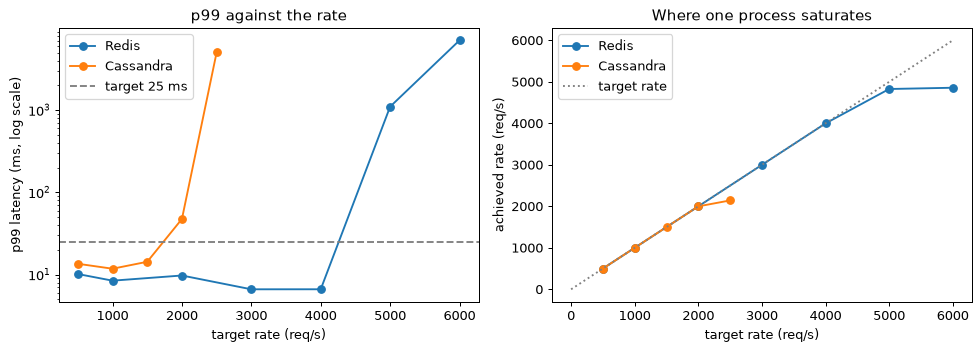

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=90)
for name, frame in frames.items():
    axes[0].plot(frame.index, frame["p99_ms"], marker="o", label=name)
    axes[1].plot(frame.index, frame["achieved_rps"], marker="o", label=name)
axes[0].axhline(25, color="grey", linestyle="--", label="target 25 ms")
axes[0].set_yscale("log")
axes[0].set_xlabel("target rate (req/s)")
axes[0].set_ylabel("p99 latency (ms, log scale)")
axes[0].set_title("p99 against the rate")
axes[0].legend()
axes[1].plot([0, 6000], [0, 6000], color="grey", linestyle=":", label="target rate")
axes[1].set_xlabel("target rate (req/s)")
axes[1].set_ylabel("achieved rate (req/s)")
axes[1].set_title("Where one process saturates")
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. What changed the numbers: reading Redis on the event loop

Change 6 moved the Redis read from a worker thread to the event loop. The A/B ran base and new
alternately in one session, three runs per rate (`docs/benchmarks.md`, Change 6).

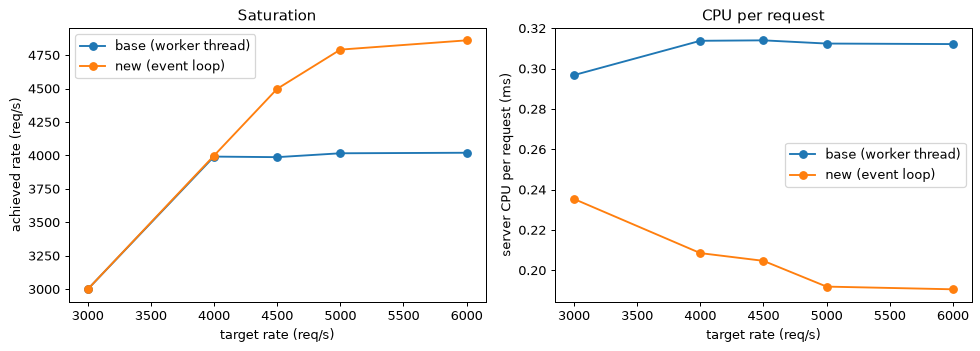

In [10]:
_, base = load("change6-base-1-514f735.json")
_, new = load("change6-new-1-5793a15.json")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=90)
axes[0].plot(base.index, base["achieved_rps"], marker="o", label="base (worker thread)")
axes[0].plot(new.index, new["achieved_rps"], marker="o", label="new (event loop)")
axes[0].set_xlabel("target rate (req/s)")
axes[0].set_ylabel("achieved rate (req/s)")
axes[0].set_title("Saturation")
axes[0].legend()
axes[1].plot(base.index, base["cpu_ms_per_request"], marker="o", label="base (worker thread)")
axes[1].plot(new.index, new["cpu_ms_per_request"], marker="o", label="new (event loop)")
axes[1].set_xlabel("target rate (req/s)")
axes[1].set_ylabel("server CPU per request (ms)")
axes[1].set_title("CPU per request")
axes[1].legend()
plt.tight_layout()
plt.show()

## What this tour does not show

- The streaming job: Kafka and the generic Flink job need the Compose stack (`docs/demo.md`, Demo B and C).
- The Spark backfill and the training datasets in both modes: they need Spark and the Iceberg history
  (`docs/demo.md`, Demo C and D).
- A real Redis: the stand-in above shows the contract, and `make quickstart` runs it against Redis.
- Production numbers: the measurements are one laptop, one process and local databases.